# Mantel's theorem -> Turan graphs

The split-and-multiply question from `quarter_square_semicircle.ipynb` has a graph-theory reading: split n vertices into 2 groups of sizes a and b, connect every cross-pair, never connect within a group. That's the complete bipartite graph K(a,b), and it has exactly a*b edges.

**Mantel's theorem** (1907) says the split that maximizes edges while keeping the graph triangle-free is the most even one -- floor(n/2) and ceil(n/2) -- matching the quarter-square peak from the other notebook.

**Turan's theorem** generalizes it: split n vertices into r nearly-equal groups instead of 2, connect everything across groups. That graph (the Turan graph T(n,r)) is the extremal graph with no clique of size r+1. r=2 recovers Mantel. `networkx` ships `nx.turan_graph(n, r)` directly.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

n = 7

def choose2(k):
    return k * (k - 1) // 2

def expected_edges(n, r):
    # complement counting: all pairs minus within-group pairs, most-even split
    base, extra = divmod(n, r)
    sizes = [base + 1] * extra + [base] * (r - extra)
    return choose2(n) - sum(choose2(s) for s in sizes), sizes

for r in range(2, n + 1):
    G = nx.turan_graph(n, r)
    expected, sizes = expected_edges(n, r)
    assert G.number_of_edges() == expected, (r, G.number_of_edges(), expected)
    if r == 2:
        triangle_count = sum(nx.triangles(G).values()) // 3
        assert triangle_count == 0, "Mantel's graph must be triangle-free"
        assert G.number_of_edges() == 12, "n=7 max should be 3x4=12"

print("Turan edge counts + Mantel triangle-free check passed for n=7, r=2..7")

Turan edge counts + Mantel triangle-free check passed for n=7, r=2..7


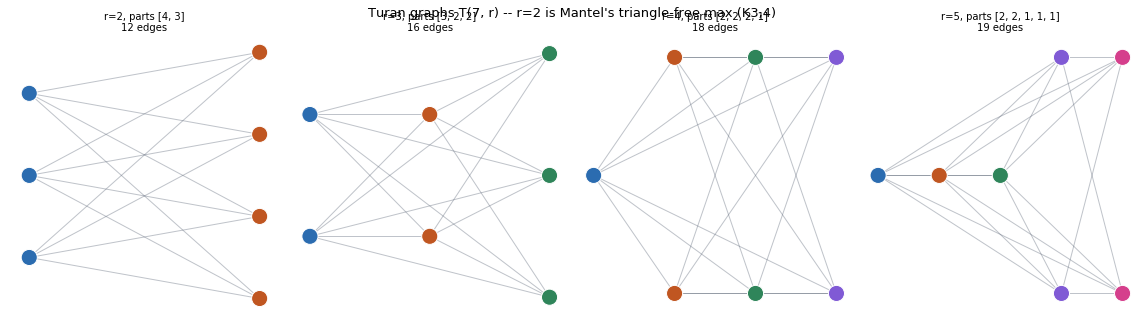

In [2]:
def block_layout(G):
    # column per group, nodes stacked and centered within the column
    blocks = {}
    for v in G.nodes:
        blocks.setdefault(G.nodes[v]["subset"], []).append(v)
    pos = {}
    for bi, nodes in blocks.items():
        for j, v in enumerate(nodes):
            pos[v] = (bi, j - (len(nodes) - 1) / 2)
    return pos

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
rs = [2, 3, 4, 5]
group_colors = ["#2b6cb0", "#c05621", "#2f855a", "#805ad5", "#d53f8c"]

for ax, r in zip(axes, rs):
    G = nx.turan_graph(n, r)
    pos = block_layout(G)
    colors = [group_colors[G.nodes[v]["subset"] % len(group_colors)] for v in G.nodes]
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, edge_color="#4a5568")
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=260,
                            edgecolors="white", linewidths=1)
    _, sizes = expected_edges(n, r)
    ax.set_title(f"r={r}, parts {sizes}\n{G.number_of_edges()} edges", fontsize=10)
    ax.axis("off")

fig.suptitle(f"Turan graphs T({n}, r) -- r=2 is Mantel's triangle-free max (K3,4)", fontsize=13)
fig.tight_layout()
fig.savefig("mantel_turan_graphs.png", dpi=150)
plt.show()

The r=2 panel is exactly the 3,4 split this started from: 12 edges, no triangle possible. As r grows, edge count keeps climbing (fewer forbidden within-group pairs) but the thing being avoided also grows -- K(r+1), not just a triangle -- so more edges stops meaning "more extreme" past r=2, it means a different, weaker constraint.